# Probability and Statistics Lab 2: random variables, and limit theorems

## General comments and instructions

-   The report must be prepared as *jupyter notebook along with compiled PDF*.
-   For each task, include
    -   the statistics obtained (like sample mean or anything else you use to complete the task) as well as histograms etc to illustrate your findings;
    -   justification of your solution (e.g. refer to the corresponding theorems from probability theory); whenever applicable, provide LaTeX formulas and derivations.
    -   conclusions (e.g. how reliable your answer is, does it agree with common sense expectations etc.).
-   Not complying with these instructions may result in point deduction.


### Work breakdown:

- Liubomyr Voskalo (effort ≈ 1/3): Task 1 (Hamming code: simulation, CLT confidence interval, error histogram) and Task 4.1 (a)–(b) (Jensen's inequality, $1/\bar X$ vs $\bar Y$).

- Anton Vertyporoh (effort ≈ 1/3): Task 2 (particle decay: Poisson parameter, CLT for sample means, largest $n$ via simulation and Markov, Chernoff and CLT bounds) and Task 4.1 (c) (Q-Q plots and scatterplots).

- Yulia Yakymiv (effort ≈ 1/3): Task 3 (Geiger counter: CLT for exponential means, safe number of samples via bounds and simulation) and Task 4.2 (coin game: exact moments, simulation, confidence interval).

The work was divided evenly: each member contributed about one third of the total effort.


A **team id number** referred to in tasks is the **two-digit** ordinal number of your team on the list. We keep it for reproducible calculations.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

team_id: int = 13  # our team's number on the list

random.seed(team_id)
np.random.seed(team_id)

## Task 1. Hamming codes


In this task, we discuss the $[7, 4]$ Hamming code and investigate its reliability. That coding system can correct single errors in the transmission of 4-bit messages and proceeds as follows:

(a) given a message $m = (a_1a_2a_3a_4)$, we first encode it to a 7-bit codeword $c = mG = (x_1x_2x_3x_4x_5x_6x_7)$, where $G$ is a $4 \times 7$ generator matrix

(b) the codeword $c$ is transmitted, and $r$ is the received message

(c) $r$ is checked for errors by calculating the syndrome vector $z := rH$, for a $7 \times 3$ parity-check matrix $H$

(d) if a single error has occurred in $r$, then the binary $z = (z_1z_2z_3)$ identifies the wrong bit no. $z_1 + 2z_2 + 4z_3$; thus $(000)$ shows there was no error (or more than one), while $(110)$ means the third bit (or more than one) got corrupted

(e) if the error was identified, then we flip the corresponding bit in $r$ to get the corrected $r^* = (r_1^*r_2^*r_3^*r_4^*r_5^*r_6^*r_7^*)$; the decoded message is then $m^* := (r_3^*r_5^*r_6^*r_7^*)$.

The generator matrix $G$ and the parity-check matrix $H$ are given by

$$
G := \begin{pmatrix}
1 & 1 & 1 & 0 & 0 & 0 & 0 \\
1 & 0 & 0 & 1 & 1 & 0 & 0 \\
0 & 1 & 0 & 1 & 0 & 1 & 0 \\
1 & 1 & 0 & 1 & 0 & 0 & 1
\end{pmatrix},
\qquad
H^\top := \begin{pmatrix}
1 & 0 & 1 & 0 & 1 & 0 & 1 \\
0 & 1 & 1 & 0 & 0 & 1 & 1 \\
0 & 0 & 0 & 1 & 1 & 1 & 1
\end{pmatrix}
$$
*$GH$ must equal a zero-matrix modulo 2.*


Assume that each bit in the transmission $c \mapsto r$ gets corrupted independently of the others with probability $p = (2 + \frac{\text{team-id-number}}{4})/100$. Your task:

1. Simulate the encoding-transmission-decoding process $N$ times and find the estimate $\hat p$ of the probability $p^*$ of correct transmission of a single message $m$. Comment why, for large $N$, $\hat p$ is expected to be close to $p^*$.
2. By estimating the standard deviation of the corresponding indicator of success by the sample standard deviation and using the CLT, find the half-length $\varepsilon$ of the confidence interval $(\hat p - \varepsilon, \hat p + \varepsilon)$, which contains the true value $p^*$ with probability at least $0.95$. What choice of $N$ guarantees that $\varepsilon \le 0.03$?
3. Draw the histogram of the number $k = 0, 1, 2, 3, 4$ of errors in $m^*$ while transmitting a 4-digit binary message. Do you think the random variable that counts the number of wrong bits in a decoded message has one of the known distributions? Justify your answer.


### 1.1 Simulation of the transmission

We draw $N$ random 4-bit messages, encode them with $G$ over $\mathbb{F}_2$, flip each bit independently with probability $p$, decode with the syndrome rule, and record whether the decoded message equals the original one.

The indicator $I_i = \mathbf{1}\{m_i^* = m_i\}$ is Bernoulli with success probability $p^*$. By the **Law of Large Numbers**, $\hat p = \frac{1}{N}\sum_{i=1}^N I_i \to p^*$ almost surely as $N \to \infty$, so for large $N$ the estimate $\hat p$ is close to $p^*$.

In [2]:
np.random.seed(team_id)
random.seed(team_id)

from scipy.stats import norm, binom, ecdf

N = 1_000_000
p = (2 + team_id / 4) / 100

G = np.array([
    [1, 1, 1, 0, 0, 0, 0],
    [1, 0, 0, 1, 1, 0, 0],
    [0, 1, 0, 1, 0, 1, 0],
    [1, 1, 0, 1, 0, 0, 1],
])
H = np.array([
    [1, 0, 1, 0, 1, 0, 1],
    [0, 1, 1, 0, 0, 1, 1],
    [0, 0, 0, 1, 1, 1, 1],
]).T  # the task gives H^T, so H is 7 x 3

assert not np.any((G @ H) % 2), "G H must vanish mod 2"

M = np.random.randint(0, 2, size=(N, 4))          # messages
C = (M @ G) % 2                                    # codewords
E = (np.random.random((N, 7)) < p).astype(int)     # independent bit flips
R = (C + E) % 2                                    # received words
Z = (R @ H) % 2                                    # syndromes
pos = Z @ np.array([1, 2, 4])

Rs = R.copy()
rows = np.where(pos > 0)[0]
Rs[rows, pos[rows] - 1] ^= 1                       # flip the flagged bit
Mstar = Rs[:, [2, 4, 5, 6]]                        # m* = (r3, r5, r6, r7)

success = np.all(Mstar == M, axis=1)
p_hat = success.mean()
s_hat = success.std(ddof=1)

print(f"p = {p:.4f}")
print(f"p_hat = {p_hat:.5f}   sample sd of indicator = {s_hat:.5f}")

p = 0.0525
p_hat = 0.95151   sample sd of indicator = 0.21480


### 1.2 Confidence interval and the required $N$

By the **CLT**, $\sqrt N(\hat p - p^*)/s \approx \mathcal N(0,1)$, where $s$ is the sample standard deviation of the indicator. Hence
$$
P\big(|\hat p - p^*| \le \varepsilon\big) \approx 2\Phi\!\left(\frac{\varepsilon \sqrt N}{s}\right) - 1 \ge 0.95
\quad\Longleftrightarrow\quad
\varepsilon = z_{0.975}\frac{s}{\sqrt N},
$$
where $z_{0.975} \approx 1.96$.

To guarantee $\varepsilon \le 0.03$ we need $N \ge \left(\frac{z_{0.975}\, s}{0.03}\right)^2$.

In [3]:
z = norm.ppf(0.975)
eps = z * s_hat / np.sqrt(N)
N_needed = int(np.ceil((z * s_hat / 0.03) ** 2))

print(f"95% CI: ({p_hat - eps:.5f}, {p_hat + eps:.5f}),  "
      f"half-length eps = {eps:.5f}")
print(f"N needed for eps <= 0.03: {N_needed}")

95% CI: (0.95109, 0.95193),  half-length eps = 0.00042
N needed for eps <= 0.03: 197


### 1.3 Distribution of the number of wrong bits in the decoded message

We count $k = 0,\dots,4$ wrong bits in $m^*$ for each simulated transmission and compare the empirical frequencies with a binomial distribution $\mathrm{Bin}(4,q)$, where $q$ is the observed per-bit error rate of $m^*$.

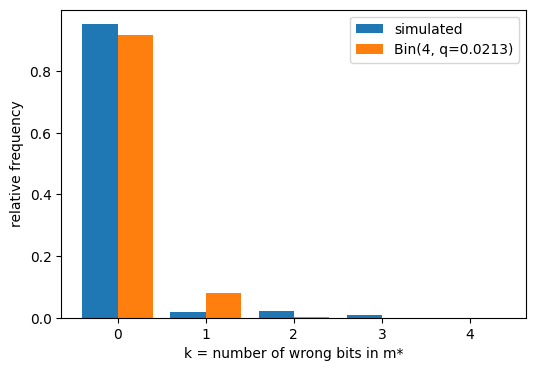

k=0: simulated 0.95151   binomial 0.91741
k=1: simulated 0.01978   binomial 0.07994
k=2: simulated 0.02062   binomial 0.00261
k=3: simulated 0.00809   binomial 0.00004
k=4: simulated 0.00000   binomial 0.00000


In [4]:
err = (Mstar != M).sum(axis=1)
k_vals = np.arange(5)
pmf_emp = np.bincount(err, minlength=5) / N
q_bit = (Mstar != M).mean()
pmf_bin = binom.pmf(k_vals, 4, q_bit)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(k_vals - 0.2, pmf_emp, width=0.4, label="simulated")
ax.bar(k_vals + 0.2, pmf_bin, width=0.4, label=f"Bin(4, q={q_bit:.4f})")
ax.set_xlabel("k = number of wrong bits in m*")
ax.set_ylabel("relative frequency")
ax.set_xticks(k_vals)
ax.legend()
plt.show()

for k, a, b in zip(k_vals, pmf_emp, pmf_bin):
    print(f"k={k}: simulated {a:.5f}   binomial {b:.5f}")

**Conclusions (Task 1).**
- With $p = 0.0525$ we get $\hat p \approx 0.9515$ with 95% CI $(0.9511, 0.9519)$, so $\varepsilon \approx 0.0004$ and the estimate is very precise. It agrees with the exact value: the $[7,4]$ Hamming code corrects every single error, and with two or more flips the decoder always lands on a wrong codeword, so a message is decoded correctly exactly when at most one of the 7 bits flips: $p^* = (1-p)^7 + 7p(1-p)^6 \approx 0.9515$, inside the interval.
- The formula gives $N \ge 197$ for $\varepsilon \le 0.03$, because the sample standard deviation is small ($\approx 0.21$). This uses the estimated $s$, so it relies on already knowing roughly what $p^*$ is. A choice that is safe without knowing $p^*$ uses the worst case $s \le 1/2$: $N \ge (1.96 \cdot 0.5 / 0.03)^2 \approx 1068$.
- The histogram is **not** binomial. The simulated frequencies are $0.0198, 0.0206, 0.0081$ for $k=1,2,3$, while $\mathrm{Bin}(4, q)$ with the same per-bit error rate predicts $0.0799, 0.0026, 0.00004$. A binomial law would need the wrong-bit indicators to be independent with a common probability. Here they are not: the decoder is a nonlinear, block-level procedure. A single flip among the message bits is repaired, so wrong bits appear only when a flip pattern makes the decoder choose a different codeword, and then several message bits are usually wrong at once. Errors therefore come in correlated clusters ($k = 2$ is even more frequent than $k = 1$), which breaks the binomial model.

## Task 2. Particle decay

In this task, we discuss a real-life process that is well modelled by a Poisson distribution. As you remember, a Poisson random variable describes occurrences of rare events, i.e., counts the number of successes in a large number of independent random experiments. One of the typical examples is the radioactive decay process.

Consider a sample of radioactive element of mass $m$, which has a large half-life period $T$; it is vitally important to know the probability that during a one second period, the number of nuclei decays will not exceed some critical level $k$. This probability can easily be estimated using the fact that, given the decay constant $\lambda$ of the element (i.e., the probability that a given nucleus decays within one second) and the number $N$ of atoms in the sample, the random number of decays within a second is well modelled by Poisson distribution with parameter $\mu := N\lambda$. Next, for the sample of mass $m$, the number of atoms is $N = \frac{m}{M} N_A$, where $N_A = 6 \times 10^{23}$ is the Avogadro constant, and $M$ is the molar (atomic) mass of the element. The decay constant, $\lambda$, is $\ln(2)/T$, where $T$ is measured in seconds.

Assume that a medical laboratory receives $n$ samples of radioactive element $^{137}\text{Cs}$ (used in radiotherapy) with half-life period $T = 30.1$ years and mass $m = (10 + \text{team-id-number}) \times 10^{-14}$ g each. Denote by $X_1, X_2, \dots, X_n$ the i.i.d. r.v.'s counting the number of decays in sample $i$ in one second.

1. Specify the parameter of the Poisson distribution of $X_i$ (you'll need the atomic mass of Cesium-137)
2. Show that the distribution of the sample means of $X_1, \dots, X_n$ gets very close to a normal one as $n$ becomes large and identify that normal distribution. To this end,
   - simulate the realization $x_1, x_2, \dots, x_n$ of the $X_i$ and calculate the sample mean $s = \bar x$;
   - repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of means and form the empirical cumulative distribution function $\hat F_{\mathbf{s}}$ of $\mathbf{s}$;
   - identify $\mu$ and $\sigma^2$ such that the c.d.f. $F$ of $\mathcal{N}(\mu, \sigma^2)$ is close to the e.c.d.f. $\hat F_{\mathbf{s}}$ and plot both c.d.f.'s on one graph to visualize their proximity (use the proper scales!);
   - calculate the maximal difference between the two c.d.f.'s;
   - consider cases $n = 5$, $n = 10$, $n = 50$ and comment on the results.
3. Calculate the largest possible value of $n$, for which the total number of decays in one second is less than $a := 100$ with probability more than $0.95$. To this end,
   - simulate the realization $x_1, x_2, \dots, x_n$ of the $X_i$ and calculate the sum $s = x_1 + \dots + x_n$;
   - repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of sums;
   - calculate the number of elements of the sample which are less than critical value ($a$) and calculate the empirical probability;
   - obtain the theoretical bound using Markov inequality, Chernoff bound and Central Limit Theorem, and compare the results.


### 2.1 Parameter of the Poisson distribution

Cesium-137 has molar mass $M \approx 137$ g/mol. The number of atoms in a sample of mass $m$ is $N_{\text{at}} = \frac{m}{M} N_A$ with $N_A = 6\cdot 10^{23}$, the decay constant is $\lambda = \ln 2 / T$ with $T = 30.1$ years in seconds, and the number of decays in one second is $X_i \sim \mathrm{Poisson}(\mu)$ with $\mu = N_{\text{at}}\lambda$.

In [5]:
team_id_task = team_id
Na = 6e23
M_cs = 137.0                                         # g/mol
T_sec = 30.1 * 365.25 * 24 * 3600                    # half-life in seconds
lam = np.log(2) / T_sec
m_sample = (10 + team_id_task) * 1e-14               # grams
N_at = m_sample / M_cs * Na
mu = N_at * lam

print(f"atoms per sample N = {N_at:.4e}")
print(f"decay constant lambda = {lam:.4e} 1/s")
print(f"Poisson parameter mu = {mu:.5f}")

atoms per sample N = 1.0073e+09
decay constant lambda = 7.2972e-10 1/s
Poisson parameter mu = 0.73504


### 2.2 CLT for the sample mean of Poisson counts

For $\bar X_n = \frac1n\sum X_i$ the CLT gives $\bar X_n \approx \mathcal N(\mu, \sigma^2)$ with $\sigma^2 = \mu/n$, since $\mathrm{Var}(X_i) = \mu$. We simulate $K = 10\,000$ sample means, plot their e.c.d.f. against the normal c.d.f., and measure the maximal gap on a grid of 200 points within $3\sigma$ of $\mu$.

n =  5: mean of means = 0.73530 (mu = 0.73504),
        var = 0.14643 (mu/n = 0.14701), max |F_s - F_Z| = 0.1334
n = 10: mean of means = 0.73316 (mu = 0.73504),
        var = 0.07400 (mu/n = 0.07350), max |F_s - F_Z| = 0.1012
n = 50: mean of means = 0.73734 (mu = 0.73504),
        var = 0.01470 (mu/n = 0.01470), max |F_s - F_Z| = 0.0342


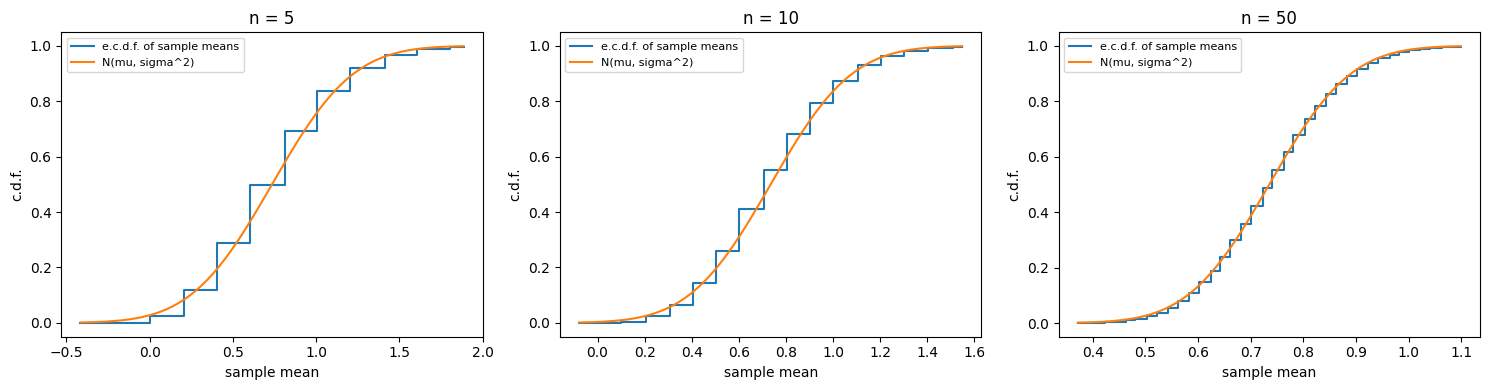

In [6]:
K = 10_000

def plot_ecdf_vs_normal(samples, mu_, sigma_, n, ax):
    Fs = ecdf(samples).cdf.evaluate
    Fz = norm(mu_, sigma_).cdf
    t = np.linspace(mu_ - 3 * sigma_, mu_ + 3 * sigma_, 200)
    ax.step(t, Fs(t), where="post", label="e.c.d.f. of sample means")
    ax.plot(t, Fz(t), label="N(mu, sigma^2)")
    ax.set_title(f"n = {n}")
    ax.set_xlabel("sample mean")
    ax.set_ylabel("c.d.f.")
    ax.legend(fontsize=8)
    return np.max(np.abs(Fs(t) - Fz(t)))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, n in zip(axes, [5, 10, 50]):
    s = np.random.poisson(mu, size=(K, n)).mean(axis=1)
    d = plot_ecdf_vs_normal(s, mu, np.sqrt(mu / n), n, ax)
    print(f"n = {n:>2}: mean of means = {s.mean():.5f} (mu = {mu:.5f}),\n"
          f"        var = {s.var(ddof=1):.5f} (mu/n = {mu / n:.5f}), "
          f"max |F_s - F_Z| = {d:.4f}")
plt.tight_layout()
plt.show()

### 2.3 Largest $n$ with total decays $< a = 100$ in one second with probability $> 0.95$

Let $S_n = X_1 + \dots + X_n$. Since $X_i$ are independent Poisson($\mu$), $S_n \sim \mathrm{Poisson}(n\mu)$.

**Simulation.** For each candidate $n$ we simulate $K$ sums and estimate $P(S_n < a)$; since this probability decreases in $n$, we locate the largest admissible $n$ by bisection.

In [7]:
a = 100

def p_below(n):
    S = np.random.poisson(mu, size=(K, n)).sum(axis=1)
    return (S < a).mean()

lo, hi = 1, 1000
while hi - lo > 1:
    mid = (lo + hi) // 2
    if p_below(mid) >= 0.95:
        lo = mid
    else:
        hi = mid
n_sim = lo
print(f"simulated: largest n with P(S_n < {a}) >= 0.95 is {n_sim}")
print(f"empirical P(S_n < {a}) at n = {n_sim}: {p_below(n_sim):.4f}")
print(f"empirical P(S_n < {a}) at n = {n_sim + 1}: "
      f"{p_below(n_sim + 1):.4f}")

simulated: largest n with P(S_n < 100) >= 0.95 is 114
empirical P(S_n < 100) at n = 114: 0.9544
empirical P(S_n < 100) at n = 115: 0.9447


**Theoretical bounds.** We want $P(S_n \ge a) \le 0.05$ or $P(S_n < a) \ge 0.95$.

* **Markov:** $P(S_n \ge a) \le \frac{E S_n}{a} = \frac{n\mu}{a}$, so $n \le \frac{0.05\, a}{\mu}$ is sufficient.
* **Chernoff:** for $S_n \sim \mathrm{Poisson}(\lambda_n)$, $\lambda_n = n\mu$, and $a > \lambda_n$, $P(S_n \ge a) \le e^{-\lambda_n}\left(\frac{e\lambda_n}{a}\right)^a$.
* **CLT:** $S_n \approx \mathcal N(n\mu, n\mu)$, so $P(S_n < a) \approx \Phi\!\left(\frac{a - n\mu}{\sqrt{n\mu}}\right) \ge 0.95$ iff $n\mu + z_{0.95}\sqrt{n\mu} \le a$.
* **CLT with continuity correction:** $S_n$ is integer-valued, so $P(S_n < a) = P(S_n \le a - 1) \approx \Phi\!\left(\frac{a - \frac12 - n\mu}{\sqrt{n\mu}}\right)$, which gives the same condition with $a - \frac12$ in place of $a$.

In [8]:
from math import exp, log
from scipy.stats import poisson

n_markov = int(np.floor(0.05 * a / mu))

def chernoff_bound(n):
    lam_n = n * mu
    return exp(-lam_n + a + a * log(lam_n / a))

n_chernoff = max(n for n in range(1, int(a / mu))
                 if chernoff_bound(n) <= 0.05)

z95 = norm.ppf(0.95)


x = (-z95 + np.sqrt(z95 ** 2 + 4 * a)) / 2
n_clt = int(np.floor(x ** 2 / mu))

x_cc = (-z95 + np.sqrt(z95 ** 2 + 4 * (a - 0.5))) / 2
n_clt_cc = int(np.floor(x_cc ** 2 / mu))

n_exact = max(n for n in range(1, int(a / mu))
              if poisson.cdf(a - 1, n * mu) >= 0.95)

print(f"Markov:   n <= {n_markov}")
print(f"Chernoff: n <= {n_chernoff}")
print(f"CLT:      n <= {n_clt}")
print(f"CLT with continuity correction: n <= {n_clt_cc}")
print(f"Simulation: n = {n_sim}")
P_n, P_next = poisson.cdf(a - 1, np.array([n_exact, n_exact + 1]) * mu)
print(f"Exact:    n = {n_exact}  (P = {P_n:.4f}; "
      f"at n = {n_exact + 1}: P = {P_next:.4f})")

Markov:   n <= 6
Chernoff: n <= 105
CLT:      n <= 115
CLT with continuity correction: n <= 114
Simulation: n = 114
Exact:    n = 114  (P = 0.9539; at n = 115: P = 0.9453)


**Conclusions (Task 2).**
- The Poisson parameter is $\mu \approx 0.735$ decays per second. The sample means have mean $\approx \mu$ and variance $\approx \mu/n$ for all three $n$ (printed above), as predicted by the CLT.
- The maximal gap between the e.c.d.f. and $\mathcal N(\mu, \mu/n)$ is $0.13$ for $n=5$, $0.10$ for $n=10$ and $0.03$ for $n=50$. It shrinks with $n$, but slowly for small $n$, because $X_i$ is discrete and skewed for small $\mu$: the sample mean takes values on a lattice with spacing $1/n$, which the continuous normal c.d.f. cannot reproduce. The approximation becomes good only for moderately large $n$.
- Largest $n$ with $P(S_n < 100) \ge 0.95$: the simulation gives $n = 114$ (empirical $0.9544$ at $n=114$ and $0.9447$ at $n=115$). Since $S_n \sim \mathrm{Poisson}(n\mu)$ exactly, we can check this with the exact c.d.f.: $P(S_n<100) = 0.9539$ at $n=114$ and $0.9453$ at $n=115$, so the **answer is $n = 114$**, in agreement with the simulation. The Monte Carlo standard error is $\sqrt{0.95 \cdot 0.05 / K} \approx 0.002$, so the empirical values match the exact ones within that accuracy.
- The bounds are $n \le 6$ (Markov), $n \le 105$ (Chernoff) and $n \le 115$ (CLT). Markov is extremely conservative because it uses only the mean. Chernoff is a valid bound but still loose. The CLT value is closest to the exact answer, but it overestimates by one, and since the CLT is an approximation and not a bound, $n = 115$ actually violates the requirement. The main reason is that $S_n$ is integer-valued: $P(S_n < 100) = P(S_n \le 99)$, so the normal approximation should be evaluated at $99.5$ rather than $100$. With this continuity correction the CLT gives $n \le 114.8$, i.e. $n = 114$, which is exactly the right answer. The value $114.8$ is still slightly above the exact threshold $n \approx 114.5$ (where $P(S_n < 100) = 0.95$ exactly); this small remaining difference comes from the right skew of the Poisson law, whose upper tail is heavier than the normal one.

## Task 3. Geiger counter

In this task, we use the Central Limit Theorem approximation for continuous random variables.

One of the devices to measure radioactivity level at a given location is the Geiger counter. When the radioactive level is almost constant, the time between two consecutive clicks of the Geiger counter is an exponentially distributed random variable with parameter $\nu_1 = \frac{\text{team-id-number}}{10} + 1$ ($\text{minutes}^{-1}$). Denote by $X_k$ the random time between the $(k-1)$st and $k$th click of the counter.

1. Show that the distribution of the sample means of $X_1, X_2, \dots, X_n$ gets very close to a normal one (which one?) as $n$ becomes large. To this end,
   - simulate the realizations $x_1, x_2, \dots, x_n$ of the r.v. $X_i$ and calculate the sample mean $s = \bar x$;
   - repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of means and then the empirical cumulative distribution function $F_{\mathbf{s}}$ of $\mathbf{s}$;
   - identify $\mu$ and $\sigma^2$ such that the c.d.f. of $\mathcal{N}(\mu, \sigma^2)$ is close to the e.c.d.f. $F_{\mathbf{s}}$ and plot both c.d.f.'s on one graph to visualize their proximity;
   - calculate the maximal difference between the two c.d.f.'s;
   - consider cases $n = 5$, $n = 10$, $n = 50$ and comment on the results.
2. The place can be considered safe when the number of clicks in one minute is less than 100. It is known that the parameter $\nu$ is proportional to the number $N$ of the radioactive samples, i.e., $\nu = N\nu_1$. Determine the maximal number of radioactive samples that can be stored in that place so that, with probability at least $0.95$, the place is identified as safe. To do this,

   (a) express the event of interest in terms of the r.v. $S := X_1 + \dots + X_{100}$;

   (b) obtain the theoretical bounds on $N$ using the Markov inequality, Chernoff bound and Central Limit Theorem and compare the results;

   (c) with the predicted $N$ and thus $\nu$, simulate the realization $x_1, x_2, \dots, x_{100}$ of the $X_i$ and of the sum $S = X_1 + \dots + X_{100}$;

   (d) repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of total times until the 100th click;

   (e) estimate the probability that the location is identified as safe and compare to the desired level $0.95$

### 3.1 CLT for the sample mean of exponential inter-click times

$X_k \sim \mathrm{Exp}(\nu_1)$ with $\nu_1 = \frac{\text{team-id}}{10} + 1$ per minute, so $E X_k = 1/\nu_1$ and $\mathrm{Var} X_k = 1/\nu_1^2$. The CLT gives $\bar X_n \approx \mathcal N\!\left(\frac{1}{\nu_1}, \frac{1}{n\nu_1^2}\right)$.

nu_1 = 2.3 clicks per minute, E X = 0.4348 min, sd X = 0.4348 min
n =  5: mean of means = 0.43524 (mu = 0.43478),
        var = 0.03781 (sigma^2 = 0.03781), max |F_s - F_Z| = 0.0608
n = 10: mean of means = 0.43358 (mu = 0.43478),
        var = 0.01887 (sigma^2 = 0.01890), max |F_s - F_Z| = 0.0457
n = 50: mean of means = 0.43496 (mu = 0.43478),
        var = 0.00379 (sigma^2 = 0.00378), max |F_s - F_Z| = 0.0228


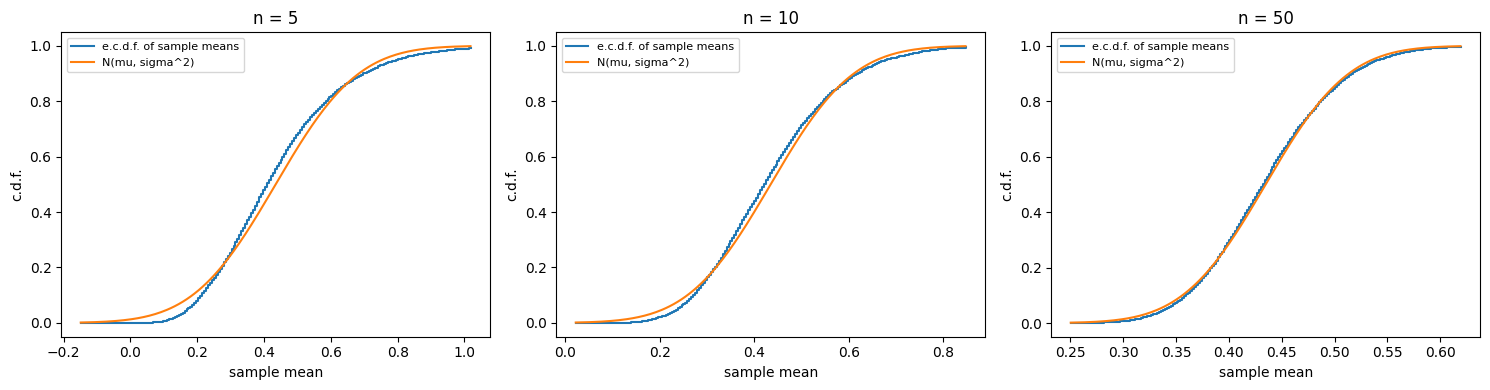

In [9]:
nu1 = team_id / 10 + 1
print(f"nu_1 = {nu1} clicks per minute, "
      f"E X = {1 / nu1:.4f} min, sd X = {1 / nu1:.4f} min")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, n in zip(axes, [5, 10, 50]):
    s = np.random.exponential(scale=1 / nu1, size=(K, n)).mean(axis=1)
    mu_t = 1 / nu1
    sigma_t = 1 / (nu1 * np.sqrt(n))
    d = plot_ecdf_vs_normal(s, mu_t, sigma_t, n, ax)
    print(f"n = {n:>2}: mean of means = {s.mean():.5f} "
          f"(mu = {mu_t:.5f}),\n"
          f"        var = {s.var(ddof=1):.5f} "
          f"(sigma^2 = {sigma_t ** 2:.5f}), "
          f"max |F_s - F_Z| = {d:.4f}")
plt.tight_layout()
plt.show()

### 3.2 Maximal number of samples $N$ for a safe place

Let $\nu = N\nu_1$ be the click rate. Then the inter-click times $X_k$ are i.i.d. $\mathrm{Exp}(\nu)$, and the number of clicks in one minute is $M_1 \sim \mathrm{Poisson}(\nu)$.

**(a) The event in terms of $S$.** The place is safe iff $M_1 < 100$, i.e. iff the 100th click happens after the first minute:
$$
\{M_1 < 100\} = \{S > 1\}, \qquad S := X_1 + \dots + X_{100}.
$$
So we need $P(S > 1) \ge 0.95$, or equivalently $P(S \le 1) \le 0.05$.

**(b) Theoretical bounds on $\nu$** (then $N \le \nu/\nu_1$):

* **Markov:** Markov's inequality only bounds upper tails, so we apply it to the equivalent count event: $P(S \le 1) = P(M_1 \ge 100) \le \frac{E M_1}{100} = \frac{\nu}{100} \le 0.05 \Rightarrow \nu \le 5$.
* **Chernoff:** for $t > 0$, $P(S \le 1) = P(e^{-tS} \ge e^{-t}) \le e^{t}\, E e^{-tS} = e^{t}\left(\frac{\nu}{\nu + t}\right)^{100}$. For $\nu < 100$ the minimum is at $t = 100 - \nu$, which gives $P(S \le 1) \le e^{-\nu}\left(\frac{e\nu}{100}\right)^{100}$. This is the same as the Chernoff bound for the Poisson count $M_1$.
* **CLT:** $E S = 100/\nu$ and $\mathrm{Var}\, S = 100/\nu^2$, so $S \approx \mathcal N(100/\nu,\ 100/\nu^2)$ and
$$
P(S > 1) \approx 1 - \Phi\!\left(\frac{1 - 100/\nu}{10/\nu}\right) = \Phi\!\left(\frac{100 - \nu}{10}\right),
$$
so $P(S > 1) \ge 0.95$ iff $\nu \le 100 - 10\, z_{0.95} \approx 83.6$.

In [10]:
def p_safe(N_samples):
    nu = N_samples * nu1
    S = np.random.exponential(scale=1 / nu, size=(K, 100)).sum(axis=1)
    return (S > 1).mean()

N_max_markov = int(np.floor(5 / nu1))

def chernoff_bound_S(n_samples):
    # Chernoff bound for P(S <= 1)
    nu = n_samples * nu1
    return exp(-nu + 100 + 100 * log(nu / 100))

N_max_chernoff = max(n for n in range(1, 100)
                     if n * nu1 < 100 and chernoff_bound_S(n) <= 0.05)

# CLT
N_max_clt = int(np.floor((100 - 10 * z95) / nu1))

N_exact = max(n for n in range(1, 100)
              if poisson.cdf(99, n * nu1) >= 0.95)

print(f"Markov:   N <= {N_max_markov}")
print(f"Chernoff: N <= {N_max_chernoff}")
print(f"CLT:      N <= {N_max_clt}")
P_N, P_next = poisson.cdf(99, np.array([N_exact, N_exact + 1]) * nu1)
print(f"Exact:    N = {N_exact}  "
      f"(P(safe) = {P_N:.4f}; at N = {N_exact + 1}: {P_next:.4f})")

Markov:   N <= 2
Chernoff: N <= 33
CLT:      N <= 36
Exact:    N = 36  (P(safe) = 0.9638; at N = 37: 0.9379)


**Simulation.** For each candidate $N$ we simulate $K$ realizations of $S = X_1 + \dots + X_{100}$ and estimate $P(S > 1)$.

In [11]:
results = {N_s: p_safe(N_s) for N_s in range(1, 101)}
N_sim = max(N_s for N_s, pr in results.items() if pr >= 0.95)

for N_s in [N_sim - 1, N_sim, N_sim + 1]:
    print(f"N = {N_s:>3}: nu = {N_s * nu1:6.2f}, "
          f"empirical P(safe) = {results[N_s]:.4f}")
print(f"simulated largest N with P(safe) >= 0.95: {N_sim}")

N =  35: nu =  80.50, empirical P(safe) = 0.9807
N =  36: nu =  82.80, empirical P(safe) = 0.9629
N =  37: nu =  85.10, empirical P(safe) = 0.9335
simulated largest N with P(safe) >= 0.95: 36


**Conclusions (Task 3).**
- Here $\nu_1 = 2.3$ per minute, so the inter-click times have mean $\approx 0.435$ min. The sample means approach the normal law $\mathcal N(1/\nu_1, 1/(n\nu_1^2))$, and the simulated variances agree with $\sigma^2$ to within one percent. The maximal c.d.f. gap is $0.061$, $0.046$ and $0.023$ for $n = 5, 10, 50$. It falls with $n$, as expected; the exponential law is skewed, so $n=5$ is still visibly non-normal.
- Safe-place rate: the simulation gives $N = 36$ (empirical $P(\text{safe}) = 0.9629$ at $N=36$, $0.9807$ at $N=35$, and $0.9335$ at $N=37$). This matches the exact value from the Poisson c.d.f. ($P = 0.964$ at $N=36$, $0.938$ at $N=37$). The exact threshold is $\nu \le 84.1$, i.e. $N \le 36.6$. Bounds: Markov $N \le 2$, Chernoff $N \le 33$, CLT $N \le 36$. The CLT gives the right answer: its threshold $\nu \le 83.6$ ($N \le 36.3$) is slightly below the exact one. The reason is that $S$ has a right-skewed Gamma distribution, whose left tail is lighter than the normal one, so the normal approximation slightly overstates $P(S \le 1)$ and is a little conservative here. The difference is too small to change the integer answer. Chernoff is a valid but conservative bound, and Markov is far too pessimistic, because it only uses the mean click rate. Because $N$ moves $\nu$ in steps of $2.3$, the probability jumps from $0.964$ to $0.938$ between $N=36$ and $N=37$, so $N = 36$ meets the requirement with some margin.

## Task 4. Expectation fallacy

This task consists of two parts:

1. In this part, we discuss independence of random variables and its moments: expectation and variance.

   (a) Suppose we have a random variable $X$. Explain why $E\left(\frac{1}{X}\right) \ne \frac{1}{E(X)}$;

   (b) Let $X \sim \mathcal{N}(\mu, \sigma^2)$ with $\mu = 5$ and $\sigma^2 = 10$. Simulate realizations $x_1, x_2, \dots, x_{100}$ of $X$ and $y_1, y_2, \dots, y_{100}$ of $Y := \frac{1}{X}$ to calculate the values of $\frac{1}{\bar X}$ and $\bar Y$. Comment on the received results;

   (c) Let $X$ and $Y$ be independent exponentially distributed r.v.'s with parameter $\lambda = 2$. Set $Z := \ln X + 5$. Plot the Quantile-Quantile plot and scatterplot of $X$ and $Y$. Plot the Quantile-Quantile plot and scatterplot of $X$ and $Z$. Explain the results. Comment on the difference of relations between the pairs of random variables. Which pair of r.v.'s is dependent and which one is identically distributed?

2. You toss a fair coin three times and a random variable $X$ records how many times the coin shows Heads. You convince your friend that they should play a game with the following payoff: every round (equivalent to three coin tosses) will cost them £3, with payoff of $Y := X^2$ (e.g., £4 for two Heads). Your friend argues: "on average there are $1.5$ Heads, so I win £$1.5^2 = $ £$2.25 <$ £$3$, hence the game is unfair". Is the game fair, i.e., is the expected value of the net gain zero? What is the variance of $Y$? To answer this,

   (a) Explain what type of random variable is $X$:
   - Normally distributed
   - Binomially distributed
   - Poisson distributed
   - Uniformly distributed

   (b) What are the expected value and variance of $X$? Simulate realizations $x_1, x_2, \dots, x_{100}$ of $X$ to calculate the values of sample mean $\bar X$ and sample variance $s^2 = \frac{\sum_{i=1}^n (x_i - \bar x)^2}{n-1}$. Comment on the results;

   (c) Is your friend's argument correct? Relate it to part 1(a). Compute the expected value and variance of $Y$ exactly. Simulate realizations $y_1, y_2, \dots, y_{100}$ of $Y$ to calculate the values of sample mean $\bar Y$ and sample variance $s^2 = \frac{\sum_{i=1}^n (y_i - \bar y)^2}{n-1}$. Comment on the results;

   (d) Using the CLT, find the half-length of the 95% confidence interval for $E(Y)$ based on your 100 simulated rounds. Could the simulation alone tell you whether the game is fair? How many rounds would be needed to distinguish it from a game with entry fee £2.9?


### 4.1 (a) $E(1/X) \neq 1/E(X)$

Expectation is linear, $E(aX + b) = aE(X) + b$, but the map $x \mapsto 1/x$ is not linear, so in general $E(1/X)$ is not $1/E(X)$. A simple example: if $X$ takes the values $1$ and $3$ with probability $\tfrac12$ each, then $E(1/X) = \tfrac12\left(1 + \tfrac13\right) = \tfrac23$, while $1/E(X) = \tfrac12$.

More precisely, $x \mapsto 1/x$ is convex on $(0,\infty)$, so by **Jensen's inequality** $E(1/X) \ge 1/E(X)$ for positive $X$, with equality only when $X$ is almost surely constant. If $X$ can take values near or below zero, $E(1/X)$ may not even exist (see part (b)).

### 4.1 (b) $X \sim \mathcal N(5, 10)$, $Y = 1/X$

In [12]:
np.random.seed(team_id)
mu_x, sigma_x = 5, np.sqrt(10)
x_s = np.random.normal(mu_x, sigma_x, size=100)
y_s = 1 / x_s

print(f"1 / X_bar = {1 / x_s.mean():.5f}")
print(f"Y_bar     = {y_s.mean():.5f}")
print(f"P(X < 0) = {norm.cdf(0, mu_x, sigma_x):.4f}")

1 / X_bar = 0.19288
Y_bar     = 0.10137
P(X < 0) = 0.0569


The two numbers differ a lot. $1/\bar X$ is close to $1/\mu = 0.2$, because $\bar X$ concentrates around $\mu$. $\bar Y$ is an average of $1/X_i$, and it is dominated by the few draws with $X_i$ close to zero, where $1/X_i$ is huge in absolute value. Since $X$ is normal, about $5.7\%$ of the draws are negative (here $5$ of $100$), so those extreme values can have either sign. In our sample the single draw $x = -0.107$ gives $1/x = -9.31$, which alone pulls $\bar Y$ down from $0.196$ to $0.101$. Jensen's inequality from part (a) does not even apply, because $X$ is not positive, and $E(Y)$ does not exist for a normal $X$ (the integral of $1/x$ near zero diverges). So $\bar Y$ never settles to a stable value, and its difference from $1/\bar X$ is not just a finite-sample effect.

### 4.1 (c) Exponential $X$, $Y$ (independent) and $Z = \ln X + 5$

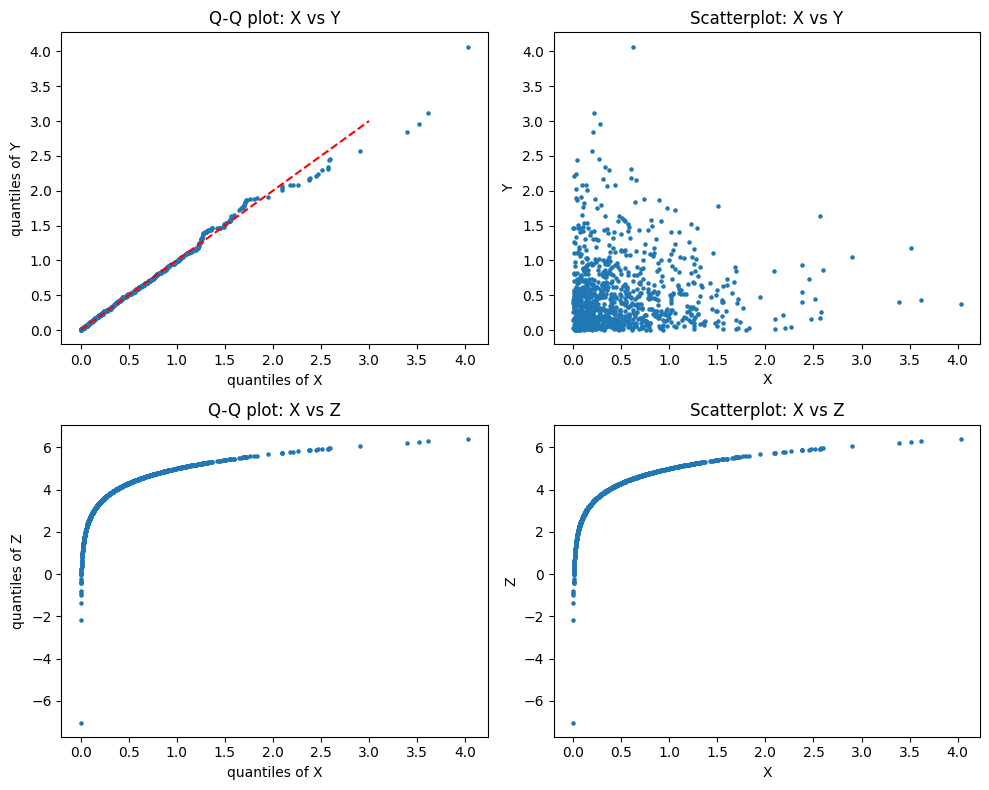

X: mean 0.4911, sd 0.5172
Y: mean 0.4950, sd 0.5018
Z: mean 3.6811, sd 1.3139


In [13]:
np.random.seed(team_id)
lam_e = 2
X = np.random.exponential(scale=1 / lam_e, size=1000)
Y = np.random.exponential(scale=1 / lam_e, size=1000)
Z_v = np.log(X) + 5

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

# Q-Q plot: sorted X against sorted Y (equal sizes)
axes[0, 0].scatter(np.sort(X), np.sort(Y), s=5)
axes[0, 0].plot([0, 3], [0, 3], "r--")
axes[0, 0].set_title("Q-Q plot: X vs Y")
axes[0, 0].set_xlabel("quantiles of X")
axes[0, 0].set_ylabel("quantiles of Y")

axes[0, 1].scatter(X, Y, s=5)
axes[0, 1].set_title("Scatterplot: X vs Y")
axes[0, 1].set_xlabel("X")
axes[0, 1].set_ylabel("Y")

axes[1, 0].scatter(np.sort(X), np.sort(Z_v), s=5)
axes[1, 0].set_title("Q-Q plot: X vs Z")
axes[1, 0].set_xlabel("quantiles of X")
axes[1, 0].set_ylabel("quantiles of Z")

axes[1, 1].scatter(X, Z_v, s=5)
axes[1, 1].set_title("Scatterplot: X vs Z")
axes[1, 1].set_xlabel("X")
axes[1, 1].set_ylabel("Z")

plt.tight_layout()
plt.show()

print(f"X: mean {X.mean():.4f}, sd {X.std(ddof=1):.4f}")
print(f"Y: mean {Y.mean():.4f}, sd {Y.std(ddof=1):.4f}")
print(f"Z: mean {Z_v.mean():.4f}, sd {Z_v.std(ddof=1):.4f}")

**Interpretation.** $X$ and $Y$ are independent and identically distributed, so their Q-Q plot lies on the diagonal (apart from the usual scatter in the few largest values) and their scatterplot shows no pattern. $Z = \ln X + 5$ is a deterministic function of $X$, so $X$ and $Z$ are strongly dependent (the scatterplot is a curve), while their distributions differ (the Q-Q plot is not the diagonal). Because $Z$ is an increasing function of $X$, sorting $X$ also sorts $Z$, so the Q-Q plot of $(X, Z)$ is exactly the same curve as their scatterplot. Hence the dependent pair is $(X, Z)$, and the identically distributed pair is $(X, Y)$.

### 4.2 Expected value of the friend's game

Let $X \sim \mathrm{Bin}(3, \tfrac12)$ be the number of Heads, $Y = X^2$, and the net gain be $G = Y - 3$. Then, exactly:

* $E X = 3/2$, $\mathrm{Var} X = 3/4$ (type of variable: **binomially distributed**).
* $Y \in \{0,1,4,9\}$ with probabilities $\tfrac18, \tfrac38, \tfrac38, \tfrac18$, so $E Y = \frac{0 + 3 + 12 + 9}{8} = 3$ and $E Y^2 = \frac{0+3+48+81}{8} = \frac{33}{2}$, hence $\mathrm{Var} Y = \frac{33}{2} - 9 = \frac{15}{2}$.

Thus $E G = E Y - 3 = 0$: **the game is fair**. The friend's argument is wrong because $E(X^2) \neq (E X)^2$, which is the same fallacy as in 4.1(a): $E(X^2) = \mathrm{Var} X + (E X)^2 = 3/4 + 9/4 = 3$.

In [14]:
np.random.seed(team_id)
n_rounds = 100
x_g = np.random.binomial(3, 0.5, size=n_rounds)
y_g = x_g ** 2

print(f"X: sample mean {x_g.mean():.4f} (exact 1.5), "
      f"sample var {x_g.var(ddof=1):.4f} (exact 0.75)")
print(f"Y: sample mean {y_g.mean():.4f} (exact 3), "
      f"sample var {y_g.var(ddof=1):.4f} (exact 7.5)")
print(f"mean net gain over 100 rounds: {y_g.mean() - 3:.4f}")

z = norm.ppf(0.975)
half = z * y_g.std(ddof=1) / np.sqrt(n_rounds)
print(f"95% CI for E(Y): ({y_g.mean() - half:.4f}, "
      f"{y_g.mean() + half:.4f}), "
      f"half-length {half:.4f}")

n_req = int(np.ceil((z * np.sqrt(7.5) / 0.05) ** 2))
print(f"rounds needed to separate E(Y) = 3 from 2.9 "
      f"(half-width 0.05): {n_req}")

X: sample mean 1.4300 (exact 1.5), sample var 0.7930 (exact 0.75)
Y: sample mean 2.8300 (exact 3), sample var 7.6173 (exact 7.5)
mean net gain over 100 rounds: -0.1700
95% CI for E(Y): (2.2891, 3.3709), half-length 0.5409
rounds needed to separate E(Y) = 3 from 2.9 (half-width 0.05): 11525


**Conclusions (Task 4).**
- **1(a)–(b).** $1/\bar X = 0.193$ while $\bar Y = 0.101$, so $E(1/X) \ne 1/E(X)$ is clearly visible. $\bar X$ concentrates near $\mu = 5$, but $\bar Y$ is driven by the few $X_i$ near zero (the normal law assigns probability $0.057$ to $X<0$); here one draw $x=-0.107$ contributes $-9.31$ and pulls $\bar Y$ far below $0.2$. For a normal $X$, $E(1/X)$ does not exist, so $\bar Y$ does not converge to a stable value.
- **1(c).** $X$ and $Y$ are independent and identically distributed (Q-Q plot on the diagonal, no pattern in the scatterplot, sample means $0.49$ and $0.50$ against the exact $0.5$). $Z = \ln X + 5$ is a function of $X$ with a different law (mean $3.68$, and the Q-Q plot is not the diagonal). So the dependent pair is $(X, Z)$, and the identically distributed pair is $(X, Y)$.
- **2(a)–(b).** $X \sim \mathrm{Bin}(3, \tfrac12)$, with $E X = 1.5$ and $\mathrm{Var}\, X = 0.75$. The simulated sample mean is $1.43$; its standard error is $\sqrt{0.75/100} \approx 0.09$, so it is within one standard error of $1.5$. The sample variance $0.79$ is close to $0.75$: using the fourth central moment $\mu_4 = 21/16$ of $X$, the standard error of the sample variance is $\sqrt{(\mu_4 - \sigma^4 \frac{n-3}{n-1})/n} \approx 0.09$, so the deviation is about half a standard error. Both values agree with the theory.
- **2(c)–(d).** The exact values are $E Y = 3$ and $\mathrm{Var}\, Y = 7.5$, so the game is fair. The friend's error is $E(X^2) \neq (E X)^2$. In the simulation, the sample mean of $Y$ is $2.83$ (an average net gain of −£0.17 per round) and the sample variance is $7.62$. The CLT 95% interval for $E(Y)$ is $(2.29, 3.37)$, half-length $0.54$, which contains both $3$ and $2.9$. So 100 rounds cannot show whether the game is fair: the small loss in our simulation is just noise, and the simulation cannot even distinguish the game from one with a £2.9 fee. To separate $E(Y)=3$ from $E(Y)=2.9$ with a $95\%$ half-width of $0.05$ we need $n \approx \left(\frac{1.96\sqrt{7.5}}{0.05}\right)^2 \approx 11\,525$ rounds.

## General instructions/hints on implementation

1. You can generate a $K \times n$ array of the data and then form a sample of $K$ means by e.g. using
```python
   s = np.random.exponential(scale=1/lam, size=(K, n)).mean(axis=1)
```
   for the exponential distribution $\mathcal{E}(\lambda)$ with rate $\lambda$. Note that NumPy uses the scale (mean) $1/\lambda$, not the rate. Similarly, `np.random.poisson(mu, size=(K, n))` gives Poisson samples.

2. The e.c.d.f. $F_S$ of the data vector `s` is
```python
   from scipy.stats import ecdf
   Fs = ecdf(s).cdf.evaluate      # callable: Fs(t)
```
3. $K$ must be at least $10000$ to generate reliable e.c.d.f.'s of sample means.
4. `scipy.stats.norm(mu, sigma).cdf` gives the c.d.f. $F_Z$ of $\mathcal{N}(\mu, \sigma^2)$. Note that the 2nd argument is the standard deviation $\sigma$.
5. To calculate the maximal difference between the two c.d.f.'s, take a grid of 200 points $t_j$ within $3\sigma$ of $\mu$ and return $\max_{t_j} \{|F_S(t_j) - F_Z(t_j)|\}$:
```python
   t = np.linspace(mu - 3*sigma, mu + 3*sigma, 200)
   np.max(np.abs(Fs(t) - Fz(t)))
```
6. To plot both c.d.f.'s on one graph, use `matplotlib.pyplot.step(t, Fs(t), where="post")` for the e.c.d.f. and `plt.plot(t, Fz(t))` for the normal c.d.f.
7. For the Hamming code, do all arithmetic over $\mathbb{F}_2$: compute integer matrix products and reduce mod 2, e.g. `c = (m @ G) % 2`, `z = (r @ H) % 2`. Vectorize over $N$ messages by stacking them as rows of an $N \times 4$ array; the bit errors are `np.random.random((N, 7)) < p`.
8. For a Q-Q plot of two samples `x` and `y` of equal size, plot `np.sort(x)` against `np.sort(y)`; for a Q-Q plot against a theoretical distribution, use `scipy.stats.probplot`.
9. Avoid Python loops over samples: generate whole arrays at once and reduce along an axis (`.mean(axis=1)`, `.sum(axis=1)`). This is both faster and closer to the mathematical formulation.